# Tempo de execução × tamanho da n-tupla — treino por épocas × one-shot

A mesma ideia do `ntuple_accuracy.ipynb`, com o **tempo** no lugar da acurácia e a **média** no lugar do melhor resultado. Os resultados são agrupados por **conjunto, binarização, `kind` (`epochs` / `oneshot`), `bits` e `address`** (a arquitetura), e em cada grupo fica o **tempo médio**:

- **one-shot**: há uma configuração por arquitetura em cada semente → média entre as sementes;
- **treino por épocas**: média entre as sementes **e** entre as configurações de b × ρ₀ × τ daquela arquitetura.

**O que o tempo mede.** É o campo `seconds` gravado pelo `run_grid.py` para cada configuração: o tempo de parede do treino (`train` no one-shot; `trainEpochs` nas épocas, já com a validação com bleaching de cada época) **mais a inferência final** (classificação com bleaching da validação e do teste). Ocasionalmente inclui a codificação dos dados (só na primeira tarefa de cada processo). As configurações rodam em paralelo (vários processos), e sementes diferentes podem ter rodado em máquinas diferentes.

**Sementes com avaliação em b fixo.** Os one-shots da semente 0 também avaliaram o baseline em b fixo (depois removido), o que infla o tempo deles. Com `EXCLUIR_SEMENTES_COM_B_FIXO = True` essas sementes saem para os **dois** modelos, para que a comparação seja feita nas mesmas sementes.

O eixo do tempo é **logarítmico**: os tempos vão de milissegundos a horas.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator

# the notebook lives in experiments/, but also works when started from the repository root
HERE = Path.cwd() if (Path.cwd() / "summarize.py").exists() else Path.cwd() / "experiments"
sys.path.insert(0, str(HERE))
import summarize as sm

RESULTS_DIR = HERE / "results"
FIGURES_DIR = HERE / "figures"
SEEDS = None  # None: every seed with results for both models; or a list, e.g. [1, 2]
EXCLUIR_SEMENTES_COM_B_FIXO = True  # seeds whose one-shots also ran the fixed-b evaluation (slower)
SAVE_FIGURES = True  # PNG and HTML in experiments/figures/
ENCODINGS = {"distributive": "Termômetro distributivo", "thermometer": "Termômetro linear"}

## Todos os tempos numa tabela e o `groupby`

In [2]:
data = sm.load(str(RESULTS_DIR))
results = pd.DataFrame([dict(
    dataset=dataset, encoding=encoding, seed=seed, kind=r["kind"], bits=r["bits"], address=r["address"],
    b=r["b"], rho0=r["rho0"], tau=r["tau"], seconds=r["seconds"],
    epochs_run=len(r["accValPerEpoch"]) if r["kind"] == "epochs" else np.nan,
    fixed_b="fixed" in r)
    for (dataset, encoding), seeds in data.items() if encoding in ENCODINGS
    for seed, rows in seeds.items() if SEEDS is None or seed in SEEDS
    for r in rows])

# a seed of a dataset/encoding enters when it has both models
both_models = results.groupby(["dataset", "encoding", "seed"])["kind"].nunique() == 2
results = results.set_index(["dataset", "encoding", "seed"]).loc[both_models[both_models].index].reset_index()

if EXCLUIR_SEMENTES_COM_B_FIXO:  # the whole seed leaves, for both models
    with_fixed = results.groupby(["dataset", "encoding", "seed"])["fixed_b"].any()
    print("sementes excluídas (one-shots com avaliação em b fixo):",
          sorted({s for (_, _, s), f in with_fixed.items() if f}) or "nenhuma")
    results = results.set_index(["dataset", "encoding", "seed"]).loc[with_fixed[~with_fixed].index].reset_index()

results["seconds_per_epoch"] = results["seconds"] / results["epochs_run"]

# group_by kind, bits and address (same architecture): mean time over seeds (and over b x rho0 x tau for epochs)
keys = ["dataset", "encoding", "kind", "bits", "address"]
mean_time = results.groupby(keys).agg(
    seconds=("seconds", "mean"), seconds_std=("seconds", "std"), configs=("seconds", "count"),
    seeds=("seed", "nunique"), epochs_run=("epochs_run", "mean"),
    seconds_per_epoch=("seconds_per_epoch", "mean")).reset_index()
print("%d conjuntos/binarizações, %d grupos; sementes usadas: %s" % (
    mean_time.groupby(["dataset", "encoding"]).ngroups, len(mean_time), sorted(results["seed"].unique())))

sementes excluídas (one-shots com avaliação em b fixo): [0]
30 conjuntos/binarizações, 1628 grupos; sementes usadas: [np.int64(1), np.int64(2)]


In [3]:
arch = ["dataset", "encoding", "bits", "address"]
epochs_t = mean_time[mean_time["kind"] == "epochs"].set_index(arch)
oneshot_t = mean_time[mean_time["kind"] == "oneshot"].set_index(arch)
both = epochs_t.join(oneshot_t, lsuffix="_epochs", rsuffix="_oneshot", how="inner").reset_index()
both["ratio"] = both["seconds_epochs"] / both["seconds_oneshot"]
table = pd.DataFrame({
    "conjunto": both["dataset"], "binarização": both["encoding"].map(ENCODINGS),
    "bits": both["bits"], "n-tupla": both["address"], "sementes": both["seeds_oneshot"],
    "épocas: tempo médio (s)": both["seconds_epochs"], "épocas: configurações": both["configs_epochs"],
    "épocas: épocas rodadas (média)": both["epochs_run_epochs"], "épocas: s por época (média)": both["seconds_per_epoch_epochs"],
    "one-shot: tempo médio (s)": both["seconds_oneshot"],
    "épocas ÷ one-shot": both["ratio"],
})
table.style.format(precision=2, decimal=",", thousands=".", na_rep="—").hide(axis="index")

conjunto,binarização,bits,n-tupla,sementes,épocas: tempo médio (s),épocas: configurações,épocas: épocas rodadas (média),épocas: s por época (média),one-shot: tempo médio (s),épocas ÷ one-shot
australian,Termômetro distributivo,2,2,2,"0,04",80,"5,97","0,01","0,02","1,73"
australian,Termômetro distributivo,2,4,2,"0,02",80,"5,69","0,00","0,00","7,26"
australian,Termômetro distributivo,2,8,2,"0,02",80,"4,96","0,00","0,00","4,69"
australian,Termômetro distributivo,2,16,2,"0,01",80,"4,65","0,00","0,00","3,34"
australian,Termômetro distributivo,2,24,2,"0,01",80,"4,00","0,00","0,02","0,55"
australian,Termômetro distributivo,2,32,2,"0,01",80,"4,00","0,00","0,00","4,34"
australian,Termômetro distributivo,4,2,2,"0,05",80,"6,31","0,01","0,01","3,64"
australian,Termômetro distributivo,4,4,2,"0,03",80,"6,25","0,00","0,01","5,10"
australian,Termômetro distributivo,4,8,2,"0,02",80,"4,90","0,00","0,00","5,62"
australian,Termômetro distributivo,4,16,2,"0,01",80,"4,90","0,00","0,00","4,32"


## Resumo por conjunto e binarização

Mediana, entre as arquiteturas, do tempo médio de cada modelo e da razão épocas ÷ one-shot (razão > 1: o treino por épocas é mais lento).

In [4]:
summary = both.groupby(["dataset", "encoding"]).agg(
    arquiteturas=("ratio", "count"),
    epochs=("seconds_epochs", "median"), oneshot=("seconds_oneshot", "median"),
    ratio_median=("ratio", "median"), ratio_min=("ratio", "min"), ratio_max=("ratio", "max"),
    epochs_slower=("ratio", lambda r: int((r > 1).sum()))).reset_index()
pd.DataFrame({
    "conjunto": summary["dataset"], "binarização": summary["encoding"].map(ENCODINGS),
    "arquiteturas": summary["arquiteturas"],
    "épocas: mediana (s)": summary["epochs"], "one-shot: mediana (s)": summary["oneshot"],
    "épocas ÷ one-shot (mediana)": summary["ratio_median"],
    "mín.": summary["ratio_min"], "máx.": summary["ratio_max"],
    "arquiteturas com épocas mais lento": summary["epochs_slower"].astype(str) + "/" + summary["arquiteturas"].astype(str),
}).sort_values(["binarização", "conjunto"]).style.format(precision=2, decimal=",", thousands=".").hide(axis="index")

conjunto,binarização,arquiteturas,épocas: mediana (s),one-shot: mediana (s),épocas ÷ one-shot (mediana),mín.,máx.,arquiteturas com épocas mais lento
australian,Termômetro distributivo,30,"0,02","0,00","5,09","0,55","13,72",29/30
blood,Termômetro distributivo,25,"0,02","0,00","3,77","0,79","7,80",24/25
christine,Termômetro distributivo,30,"38,48","4,35","8,68","3,55","32,71",30/30
fashion-mnist,Termômetro distributivo,20,"308,07","27,02","11,65","10,50","24,59",20/20
higgs,Termômetro distributivo,30,"12,04","2,84","5,21","0,05","14,30",21/30
iris,Termômetro distributivo,25,"0,00","0,00","2,20","0,27","7,93",22/25
jasmine,Termômetro distributivo,30,"0,31","0,03","7,75","3,41","12,29",30/30
jsc,Termômetro distributivo,30,"108,84","282,52","0,42","0,01","11,40",11/30
miniboone,Termômetro distributivo,30,"19,01","3,66","5,85","0,11","12,41",23/30
mnist,Termômetro distributivo,20,"278,53","27,80","11,54","8,95","20,60",20/20


## Tempo médio por conjunto — uma tabela por binarização

Média de `seconds` sobre todas as configurações de cada modelo no conjunto (arquiteturas, sementes e, nas épocas, b × ρ₀ × τ), restrita às arquiteturas que os dois modelos rodaram.

In [5]:
# every configuration of the architectures that both models ran (the same ones as in `both`)
in_both = results.set_index(arch).index.isin(both.set_index(arch).index)
per_dataset = results[in_both].groupby(["dataset", "encoding", "kind"])["seconds"].mean().unstack("kind").reset_index()


def time_table(encoding):
    sub = per_dataset[per_dataset["encoding"] == encoding].sort_values("dataset")
    return pd.DataFrame({"conjunto": sub["dataset"], "tempo One-shot (s)": sub["oneshot"], "tempo Épocas (s)": sub["epochs"]})


def show_table(table):
    return table.style.format(precision=3, decimal=",", thousands=".").hide(axis="index")

### Termômetro distributivo

In [6]:
tabela_distributivo = time_table("distributive")
show_table(tabela_distributivo)

conjunto,tempo One-shot (s),tempo Épocas (s)
australian,"0,009","0,038"
blood,"0,007","0,023"
christine,"8,003","137,393"
fashion-mnist,"41,015","638,086"
higgs,"53,444","22,197"
iris,"0,002","0,004"
jasmine,"0,072","0,484"
jsc,"3.989,428","179,085"
miniboone,"41,320","33,583"
mnist,"41,818","601,185"


### Termômetro linear

In [7]:
tabela_linear = time_table("thermometer")
show_table(tabela_linear)

conjunto,tempo One-shot (s),tempo Épocas (s)
australian,"0,015","0,038"
blood,"0,011","0,024"
christine,"6,091","120,132"
fashion-mnist,"40,627","676,600"
higgs,"69,980","21,387"
iris,"0,104","0,023"
jasmine,"0,090","0,506"
jsc,"9.110,201","256,027"
miniboone,"1.001,073","28,120"
mnist,"42,825","584,201"


## Gráficos interativos — uma figura por binarização

- **dropdown**: escolhe os **bits** da binarização mostrados em todos os painéis;
- **eixo y logarítmico** (tempo médio em segundos);
- **passe o mouse** sobre uma n-tupla para ver os dois tempos médios, a razão, o desvio-padrão, quantas configurações entraram na média e o tempo por época;
- **clique na legenda** para esconder um modelo; arraste para dar zoom.

As figuras também são salvas como `.html` em `experiments/figures/`. A exibição carrega o plotly.js pela internet (CDN).

In [8]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

# reference palette: categorical slots 1-2 for the two models and chart chrome (light surface)
MODEL_COLORS = {"epochs": "#2a78d6", "oneshot": "#eb6834"}
MODEL_LABELS = {"epochs": "treino por épocas (média de b × ρ₀ × τ e sementes)", "oneshot": "one-shot (média das sementes)"}
CHROME = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
              grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
PANEL_HEIGHT, TOP_MARGIN = 280, 150  # px; the title, the dropdown and the legend live in the top margin
SEEDS_TAG = "seeds" + "-".join(map(str, sorted(results["seed"].unique())))  # suffix of the saved figures


def pt(value, decimals=2):
    return "{:,.{}f}".format(value, decimals).replace(",", "_").replace(".", ",").replace("_", ".")


def interactive_time(encoding, ncols=4, default_bits=None):
    """small multiples of one encoding, with a dropdown that chooses the bits shown in every panel"""
    sub = both[both["encoding"] == encoding]
    datasets = sorted(sub["dataset"].unique())
    bits_values = sorted(sub["bits"].unique())
    # default: the bits present in the most datasets (ties: more bits)
    coverage = {b: sub.loc[sub["bits"] == b, "dataset"].nunique() for b in bits_values}
    default_bits = default_bits if default_bits in bits_values else max(bits_values, key=lambda b: (coverage[b], b))
    nrows = -(-len(datasets) // ncols)
    fig = make_subplots(rows=nrows, cols=ncols, subplot_titles=datasets, horizontal_spacing=0.05,
                        vertical_spacing=min(0.2, 90 / (PANEL_HEIGHT * nrows)))

    trace_bits = []
    for i, dataset in enumerate(datasets):
        row, col = i // ncols + 1, i % ncols + 1
        for bits in bits_values:
            g = sub[(sub["dataset"] == dataset) & (sub["bits"] == bits)].sort_values("address")
            for kind in ("oneshot", "epochs"):
                if kind == "epochs":
                    custom = [[pt(m), pt(0 if np.isnan(s) else s), int(c), pt(r), pt(e, 1), pt(spe)] for m, s, c, r, e, spe in zip(
                        g["seconds_epochs"], g["seconds_std_epochs"], g["configs_epochs"], g["ratio"],
                        g["epochs_run_epochs"], g["seconds_per_epoch_epochs"])]
                    hover = ("<b>épocas</b>: %{customdata[0]} s (dp %{customdata[1]}, %{customdata[2]} configurações)"
                             "<br>%{customdata[4]} épocas em média · %{customdata[5]} s por época"
                             "<br>épocas ÷ one-shot: %{customdata[3]}×<extra></extra>")
                else:
                    custom = [[pt(m), pt(0 if np.isnan(s) else s), int(c)] for m, s, c in zip(
                        g["seconds_oneshot"], g["seconds_std_oneshot"], g["seeds_oneshot"])]
                    hover = "<b>one-shot</b>: %{customdata[0]} s (dp %{customdata[1]}, %{customdata[2]} sementes)<extra></extra>"
                fig.add_trace(go.Scatter(
                    x=g["address"], y=g["seconds_" + kind], mode="lines+markers",
                    name=MODEL_LABELS[kind], legendgroup=kind, showlegend=(i == 0),
                    line=dict(color=MODEL_COLORS[kind], width=2),
                    marker=dict(size=8, color=MODEL_COLORS[kind], line=dict(color=CHROME["surface"], width=2)),
                    customdata=custom, hovertemplate=hover, visible=(bits == default_bits)), row=row, col=col)
                trace_bits.append(bits)

    title = "%s — tempo médio por configuração (treino + inferência), %s" % (ENCODINGS[encoding], SEEDS_TAG.replace("seeds", "sementes ").replace("-", ", "))
    buttons = [dict(label="%d bits" % bits, method="update",
                    args=[{"visible": [b == bits for b in trace_bits]}, {"title.text": "%s — %d bits" % (title, bits)}])
               for bits in bits_values]
    height = PANEL_HEIGHT * nrows + TOP_MARGIN + 50
    controls_y = 1 + 62 / (PANEL_HEIGHT * nrows)
    fig.update_layout(
        title=dict(text="%s — %d bits" % (title, default_bits), x=0.01, xanchor="left", y=1 - 14 / height, yanchor="top",
                   font=dict(size=16, color=CHROME["primary"])),
        updatemenus=[dict(buttons=buttons, direction="down", active=bits_values.index(default_bits), showactive=True,
                          x=0.0, xanchor="left", y=controls_y, yanchor="middle", pad=dict(t=0, b=0),
                          bgcolor=CHROME["surface"], bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"]))],
        annotations=list(fig.layout.annotations) + [dict(
            text="bits da binarização", x=0.0, y=1 + 90 / (PANEL_HEIGHT * nrows), xref="paper", yref="paper",
            xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=11, color=CHROME["muted"]))],
        legend=dict(orientation="h", x=0.11, xanchor="left", y=controls_y, yanchor="middle", font=dict(color=CHROME["primary"])),
        height=height, margin=dict(l=70, r=20, t=TOP_MARGIN, b=50),
        paper_bgcolor=CHROME["surface"], plot_bgcolor=CHROME["surface"], separators=",.",
        font=dict(family="system-ui, -apple-system, 'Segoe UI', sans-serif", size=12, color=CHROME["secondary"]),
        hovermode="x unified",
        hoverlabel=dict(bgcolor="white", bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"])))
    fig.update_xaxes(tickmode="array", tickvals=sorted(sub["address"].unique()), showgrid=False,
                     linecolor=CHROME["axis"], ticks="outside", tickcolor=CHROME["axis"], tickfont=dict(color=CHROME["muted"]))
    fig.update_yaxes(type="log", gridcolor=CHROME["grid"], linecolor=CHROME["axis"], zeroline=False,
                     tickfont=dict(color=CHROME["muted"]), exponentformat="power", dtick=1)
    for r in range(1, nrows + 1):
        fig.update_yaxes(title_text="tempo médio (s, log)", row=r, col=1)
    for c in range(1, ncols + 1):
        fig.update_xaxes(title_text="tamanho da n-tupla", row=nrows, col=c)
    for k, a in enumerate(fig.layout.annotations):  # subplot titles, left-aligned over their panel
        if a.text in datasets:
            axis = fig.layout["xaxis" if k == 0 else "xaxis%d" % (k + 1)]
            a.update(x=axis.domain[0], xanchor="left", font=dict(size=13, color=CHROME["primary"]))

    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.write_html(FIGURES_DIR / ("ntuple_time_%s_%s.html" % (encoding, SEEDS_TAG)), include_plotlyjs="cdn",
                       config={"displaylogo": False})
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, config={"displaylogo": False})))
    return fig

In [9]:
interactive_time("distributive");

In [10]:
interactive_time("thermometer");

## Figuras estáticas (PNG) — todos os bits no mesmo painel

Cor = bits da binarização; linha cheia = treino por épocas, tracejada = one-shot; eixo y logarítmico. Salvas em `experiments/figures/` para uso no texto.

In [11]:
# reference palette: one categorical slot per number of bits (fixed by value, so a bits value keeps its color)
BITS_COLORS = {4: "#2a78d6", 8: "#eb6834", 16: "#1baf7a", 2: "#6250d6", 32: "#e87ba4"}
STYLES = {"epochs": "-", "oneshot": (0, (4, 3))}
MODEL_NAMES = {"epochs": "treino por épocas (média)", "oneshot": "one-shot (média)"}
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
           grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9,
    "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"],
    "axes.edgecolor": INK["axis"], "axes.labelcolor": INK["secondary"],
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "text.color": INK["primary"],
})
SECONDS = FuncFormatter(lambda v, _: ("%g" % v).replace(".", ","))


def legend_handles():
    bits = sorted(mean_time["bits"].unique())
    return ([Line2D([], [], color=BITS_COLORS[b], lw=2, marker="o", ms=6, mec=INK["surface"], label="%d bits" % b) for b in bits]
            + [Line2D([], [], color=INK["secondary"], lw=1.6, ls=STYLES[k], label=MODEL_NAMES[k]) for k in STYLES])


def plot_panel(ax, dataset, encoding, title=None):
    group = mean_time[(mean_time["dataset"] == dataset) & (mean_time["encoding"] == encoding)].sort_values("address")
    for bits in sorted(group["bits"].unique()):
        for kind in ("oneshot", "epochs"):
            g = group[(group["bits"] == bits) & (group["kind"] == kind)]
            ax.plot(g["address"], g["seconds"], color=BITS_COLORS.get(bits, INK["secondary"]), ls=STYLES[kind],
                    lw=2 if kind == "epochs" else 1.6, marker="o", ms=5.5 if kind == "epochs" else 4.5,
                    mec=INK["surface"], mew=1.2, solid_capstyle="round", solid_joinstyle="round",
                    zorder=4 if kind == "epochs" else 3, clip_on=False)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.yaxis.set_major_formatter(SECONDS)
    addresses = sorted(group["address"].unique())
    ax.set_xticks(addresses)
    ax.set_xlim(min(addresses) - 1.5, max(addresses) + 1.5)
    ax.grid(axis="y", which="major", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title or dataset, loc="left", fontsize=10, fontweight="semibold", color=INK["primary"])


def plot_encoding(encoding, ncols=4):
    datasets = sorted(mean_time.loc[mean_time["encoding"] == encoding, "dataset"].unique())
    if not datasets:
        return None
    nrows = -(-len(datasets) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.0 * nrows), squeeze=False)
    for ax, dataset in zip(axes.flat, datasets):
        plot_panel(ax, dataset, encoding)
    for ax in axes.flat[len(datasets):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("tempo médio (s, log)")
    for ax in axes[-1, :]:
        ax.set_xlabel("tamanho da n-tupla")
    fig.suptitle("%s — tempo médio por configuração (treino + inferência), %s" % (
        ENCODINGS[encoding], SEEDS_TAG.replace("seeds", "sementes ").replace("-", ", ")),
        x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.01, 0.965), ncol=7, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=1.6)
    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / ("ntuple_time_%s_%s.png" % (encoding, SEEDS_TAG)), dpi=200, facecolor=INK["surface"])
    return fig

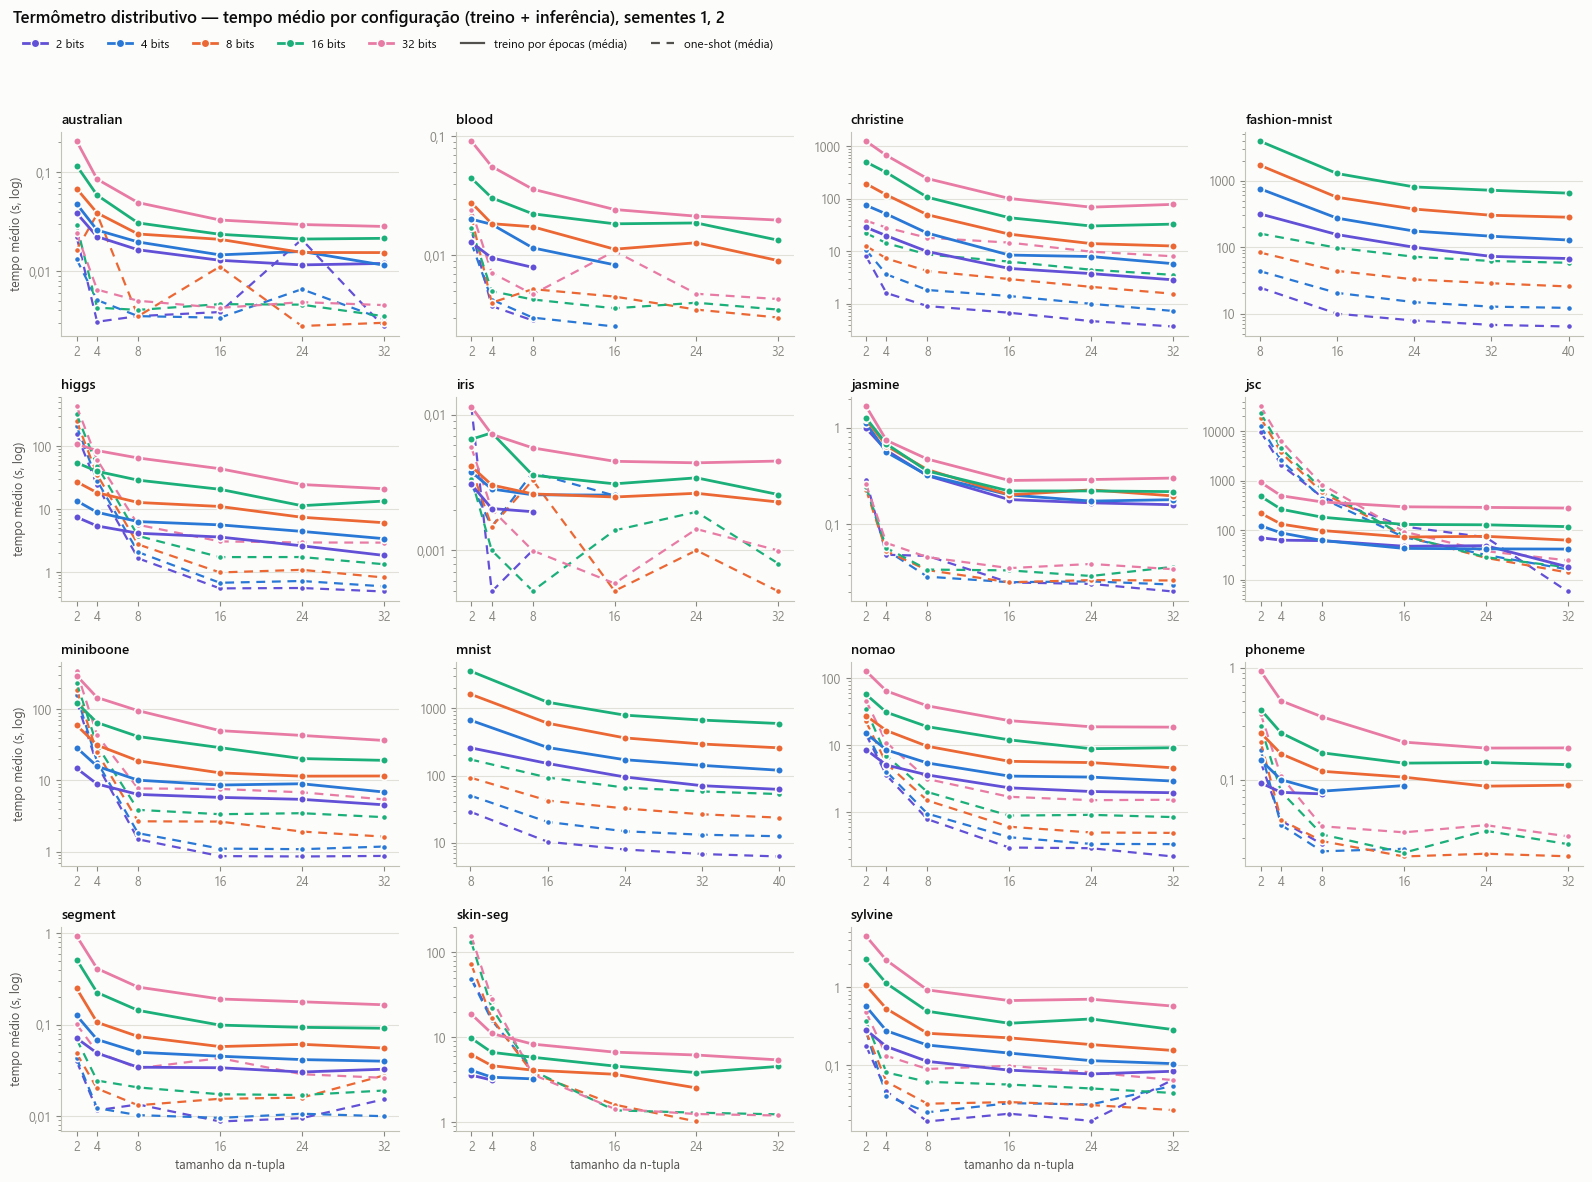

In [12]:
plot_encoding("distributive");

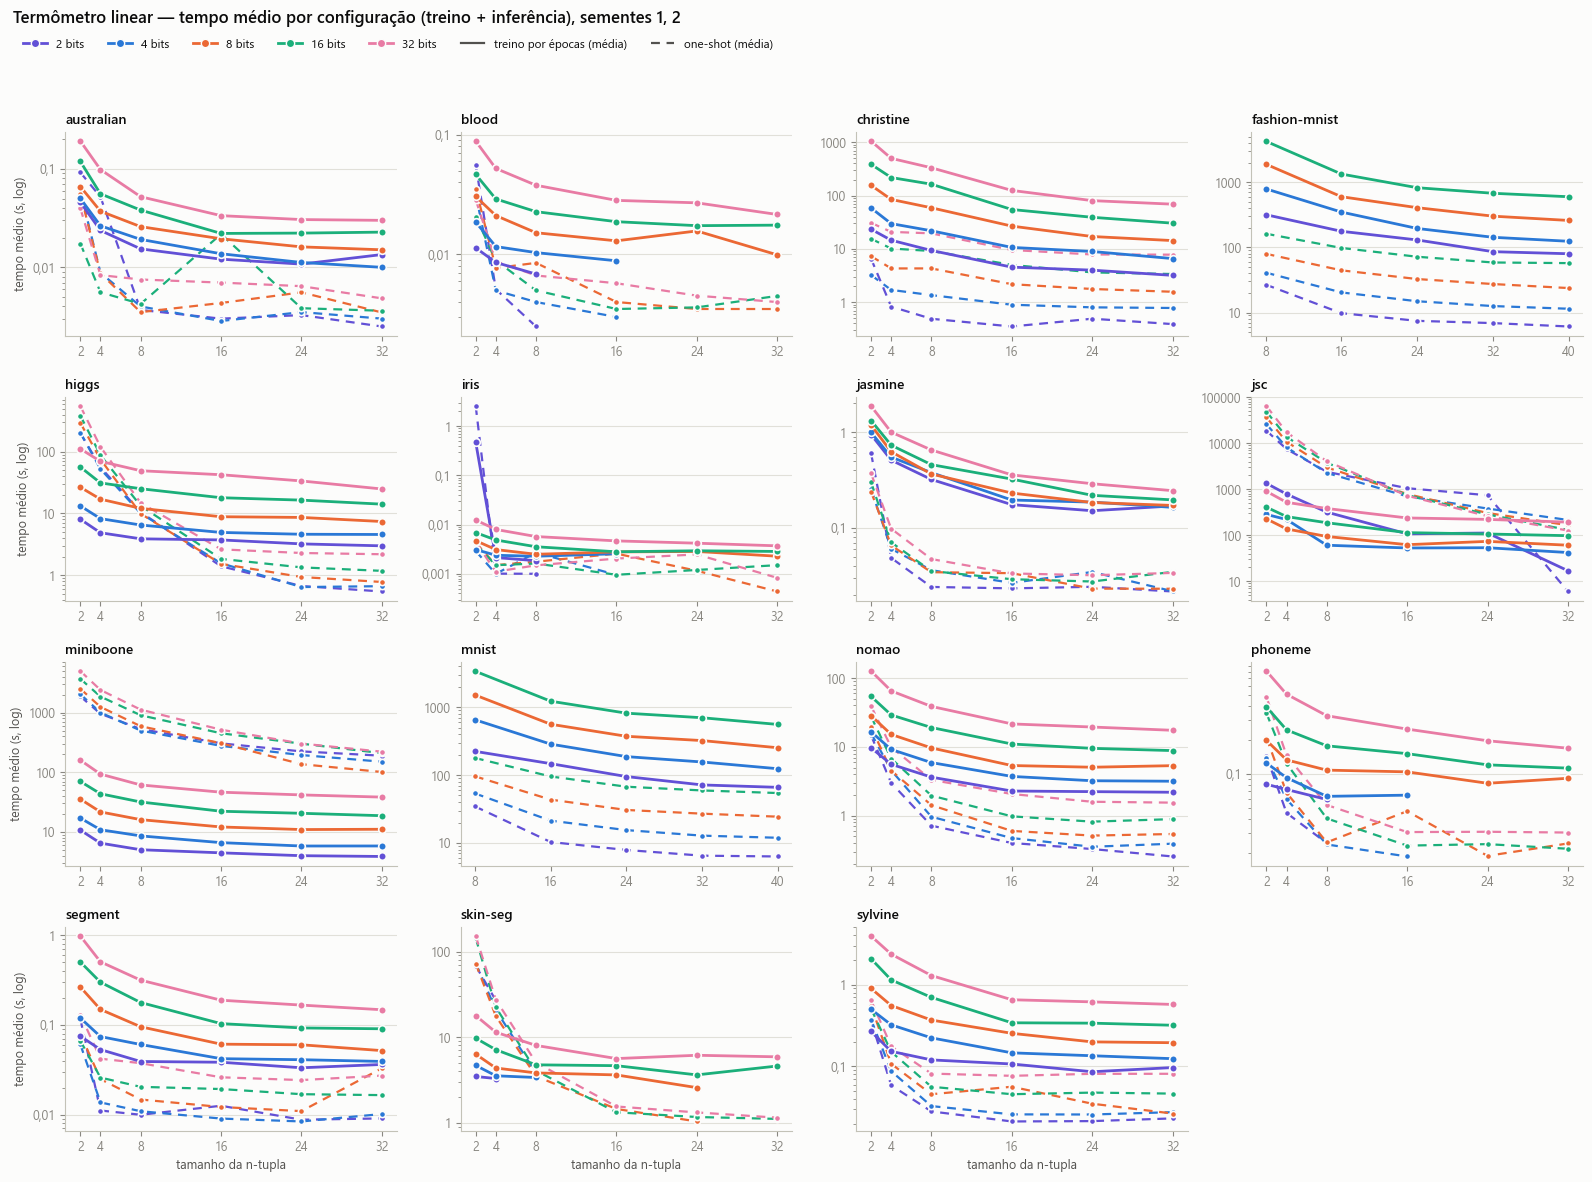

In [13]:
plot_encoding("thermometer");

## Um conjunto, as duas binarizações lado a lado

Troque o nome para ver outro conjunto (os nomes estão na tabela acima).

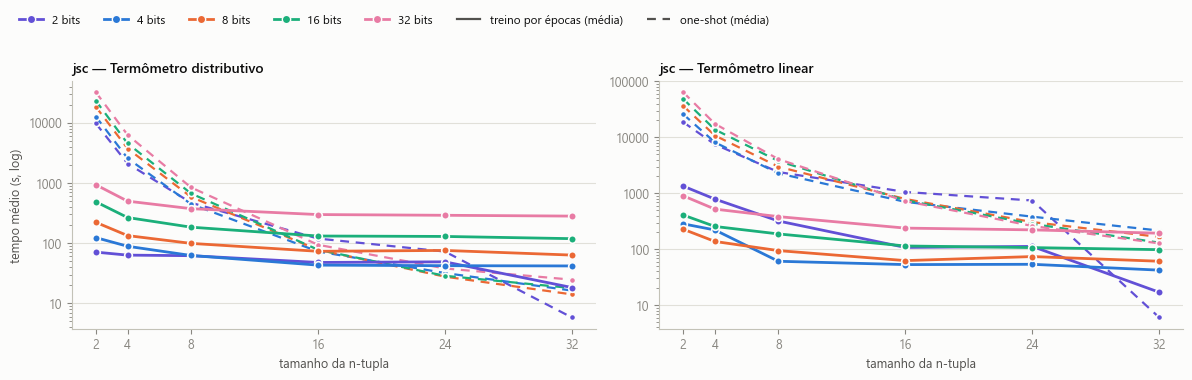

In [14]:
def plot_dataset(dataset):
    encodings = [e for e in ENCODINGS if ((mean_time["dataset"] == dataset) & (mean_time["encoding"] == e)).any()]
    fig, axes = plt.subplots(1, len(encodings), figsize=(6.0 * len(encodings), 3.8), squeeze=False)
    for ax, encoding in zip(axes[0], encodings):
        plot_panel(ax, dataset, encoding, title="%s — %s" % (dataset, ENCODINGS[encoding]))
        ax.set_xlabel("tamanho da n-tupla")
    axes[0, 0].set_ylabel("tempo médio (s, log)")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.01, 1.0), ncol=7, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    return fig


plot_dataset("jsc");